# OULAD exploratory data analysis

Descriptive analysis of recorded assessment scores. These assessment rows are repeated observations of students, not independent students. Full-data plots describe the dataset; predictive preprocessing and model selection belong inside the training partitions in the modeling notebook. No statistical significance or causal effects are established here.


Import the necessary libraries

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

DATA_DIR = Path('data') if Path('data/studentInfo.csv').exists() else Path('notebook/data')


Load the applicable datasets

In [2]:
assessments = pd.read_csv(DATA_DIR / "assessments.csv")
studentAssessment = pd.read_csv(DATA_DIR / "studentAssessment.csv")
studentInfo = pd.read_csv(DATA_DIR / "studentInfo.csv")

Inspect each of the datasets

In [3]:
assessments.head()

,code_module,code_presentation,id_assessment,assessment_type,date,weight
0,AAA,2013J,1752,TMA,19.0,10.0
1,AAA,2013J,1753,TMA,54.0,20.0
2,AAA,2013J,1754,TMA,117.0,20.0
3,AAA,2013J,1755,TMA,166.0,20.0
4,AAA,2013J,1756,TMA,215.0,30.0


In [4]:
assessments.info()

<class 'pandas.DataFrame'>
RangeIndex: 206 entries, 0 to 205
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   code_module        206 non-null    str    
 1   code_presentation  206 non-null    str    
 2   id_assessment      206 non-null    int64  
 3   assessment_type    206 non-null    str    
 4   date               195 non-null    float64
 5   weight             206 non-null    float64
dtypes: float64(2), int64(1), str(3)
memory usage: 9.8 KB


In [5]:
studentAssessment.head()

,id_assessment,id_student,date_submitted,is_banked,score
0,1752,11391,18,0,78.0
1,1752,28400,22,0,70.0
2,1752,31604,17,0,72.0
3,1752,32885,26,0,69.0
4,1752,38053,19,0,79.0


In [6]:
studentAssessment.info()

<class 'pandas.DataFrame'>
RangeIndex: 173912 entries, 0 to 173911
Data columns (total 5 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   id_assessment   173912 non-null  int64  
 1   id_student      173912 non-null  int64  
 2   date_submitted  173912 non-null  int64  
 3   is_banked       173912 non-null  int64  
 4   score           173739 non-null  float64
dtypes: float64(1), int64(4)
memory usage: 6.6 MB


In [7]:
studentInfo.head()

,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y,Withdrawn
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,Pass
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,Pass


In [8]:
studentInfo.info()

<class 'pandas.DataFrame'>
RangeIndex: 32593 entries, 0 to 32592
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   code_module           32593 non-null  str  
 1   code_presentation     32593 non-null  str  
 2   id_student            32593 non-null  int64
 3   gender                32593 non-null  str  
 4   region                32593 non-null  str  
 5   highest_education     32593 non-null  str  
 6   imd_band              31482 non-null  str  
 7   age_band              32593 non-null  str  
 8   num_of_prev_attempts  32593 non-null  int64
 9   studied_credits       32593 non-null  int64
 10  disability            32593 non-null  str  
 11  final_result          32593 non-null  str  
dtypes: int64(3), str(9)
memory usage: 3.0 MB


Join all three datasets

In [9]:
CombinedFile1 = pd.merge(
    studentAssessment,
    assessments,
    on="id_assessment",
    how="left",
    validate="many_to_one",
)
CombinedFile1.head()

,id_assessment,id_student,date_submitted,is_banked,score,code_module,code_presentation,assessment_type,date,weight
0,1752,11391,18,0,78.0,AAA,2013J,TMA,19.0,10.0
1,1752,28400,22,0,70.0,AAA,2013J,TMA,19.0,10.0
2,1752,31604,17,0,72.0,AAA,2013J,TMA,19.0,10.0
3,1752,32885,26,0,69.0,AAA,2013J,TMA,19.0,10.0
4,1752,38053,19,0,79.0,AAA,2013J,TMA,19.0,10.0


In [10]:
CombinedFile2 = pd.merge(
    CombinedFile1,
    studentInfo,
    on=["id_student", "code_module", "code_presentation"],
    how="left",
    validate="many_to_one",
)

assert len(CombinedFile2) == len(studentAssessment)

Save the final result as a csv file

In [11]:
CombinedFile2.to_csv(DATA_DIR / "combinedfile.csv",index=False)

Inspect the combined file

In [12]:
combinedfile = pd.read_csv(DATA_DIR / "combinedfile.csv")
combinedfile.info()

<class 'pandas.DataFrame'>
RangeIndex: 173912 entries, 0 to 173911
Data columns (total 19 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   id_assessment         173912 non-null  int64  
 1   id_student            173912 non-null  int64  
 2   date_submitted        173912 non-null  int64  
 3   is_banked             173912 non-null  int64  
 4   score                 173739 non-null  float64
 5   code_module           173912 non-null  str    
 6   code_presentation     173912 non-null  str    
 7   assessment_type       173912 non-null  str    
 8   date                  171047 non-null  float64
 9   weight                173912 non-null  float64
 10  gender                173912 non-null  str    
 11  region                173912 non-null  str    
 12  highest_education     173912 non-null  str    
 13  imd_band              166215 non-null  str    
 14  age_band              173912 non-null  str    
 15  num_of_prev

Find how many nulls there are

In [13]:
combinedfile.isna().sum().sum()

np.int64(10735)

Deal with the nulls appropriately (i.e. dropping null scores, adding "unknown" category to imd_band)

In [14]:
combinedfile = combinedfile.dropna(subset=["score"]).copy()
combinedfile["imd_band"] = combinedfile["imd_band"].fillna("Unknown")


In [15]:
combinedfile.isna().sum().sum()

np.int64(2865)

In [16]:
combinedfile.isna().sum()

id_assessment              0
id_student                 0
date_submitted             0
is_banked                  0
score                      0
code_module                0
code_presentation          0
assessment_type            0
date                    2865
weight                     0
gender                     0
region                     0
highest_education          0
imd_band                   0
age_band                   0
num_of_prev_attempts       0
studied_credits            0
disability                 0
final_result               0
dtype: int64

Inspect missing deadlines. The next cell counts these rows; it does not remove them.


In [17]:
print(combinedfile.loc[
    combinedfile["date"].isna(),
    ["assessment_type", "code_module"]
].value_counts())


assessment_type  code_module
Exam             CCC            1915
                 DDD             950
Name: count, dtype: int64


Check to see how many exam result rows have recorded deadlines.

In [18]:
pd.crosstab(
    combinedfile["assessment_type"],
    combinedfile["date"].isna(),
).rename(columns={False: "Deadline present", True: "Deadline missing"})

date,Deadline present,Deadline missing
assessment_type,,
CMA,70527,0
Exam,2094,2865
TMA,98253,0


Retain exam records with missing deadlines. In the initial model, exclude `date` and `date_submitted` from the features. Missing deadlines do not require discarding their valid target scores. A later timing-based model could use a missingness-aware approach and only information available at prediction time.


Investigate the distribution of the is_banked column.

In [19]:
combinedfile["is_banked"].value_counts()

is_banked
0    171831
1      1908
Name: count, dtype: int64

For this experiment, retain current, non-banked assessment scores and exclude carried-over scores (`is_banked == 1`). This defines the population being modeled; it is not a claim that banked records are invalid.


In [20]:
combinedfile = combinedfile.loc[combinedfile["is_banked"] == 0].copy()

In [21]:
combinedfile = combinedfile.drop("is_banked",axis=1)

Investigate score distribution

<Axes: ylabel='Frequency'>

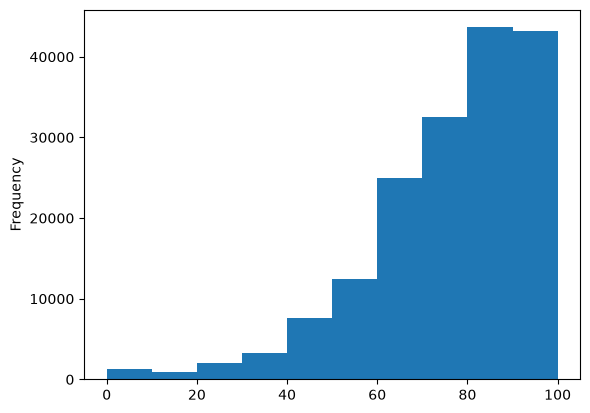

In [22]:
combinedfile["score"].plot(kind="hist")

Scores are left-skewed, with many observations in the 70–100 range. Global errors can conceal poor performance on low scores. The model notebook reports errors by score band.


Investigate the distribution of the code module as well as how correlated it is with the average score. 

In [23]:
combinedfile["code_module"].value_counts()

code_module
FFF    54149
BBB    42497
DDD    30244
CCC    18792
GGG    15199
EEE     7846
AAA     3104
Name: count, dtype: int64

<Axes: xlabel='code_module'>

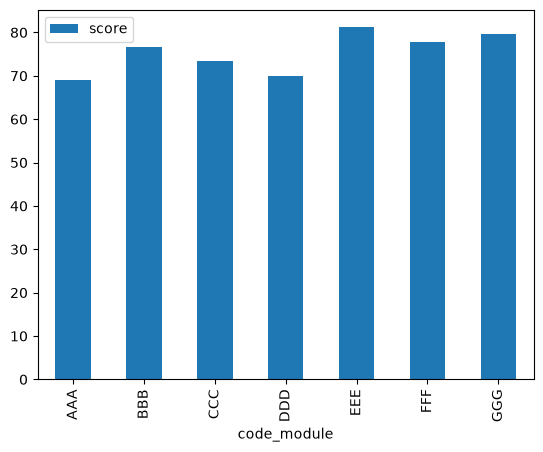

In [24]:
Module_Score = pd.DataFrame(combinedfile.groupby("code_module")["score"].mean())
Module_Score.plot(kind="bar")

The most common module is FFF while the least common is AAA.  It is evident that some modules such as EEE, FFF, and GGG have higher average scores than others such as AAA and DDD. 

Investigate the distribution of the code_presentation column as well as its relationship with the average score. 

In [25]:
combinedfile["code_presentation"].value_counts()

code_presentation
2014J    51352
2013J    48359
2014B    38440
2013B    33680
Name: count, dtype: int64

<Axes: xlabel='code_presentation'>

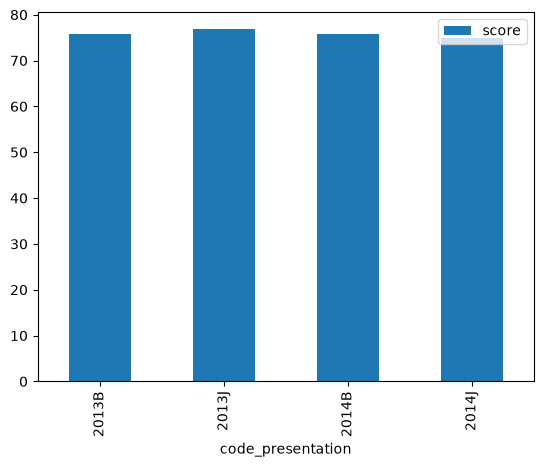

In [26]:
Presentation_Score = pd.DataFrame(combinedfile.groupby("code_presentation")["score"].mean())
Presentation_Score.plot(kind="bar")

2014J is the most common while 2013B is the least common. There is hardly any difference between the average scores for each of these presentations. 

Investigate the distribution of assessment type as well as its correlation with the average score. 

In [27]:
combinedfile["assessment_type"].value_counts()

assessment_type
TMA     96916
CMA     69956
Exam     4959
Name: count, dtype: int64

<Axes: xlabel='assessment_type'>

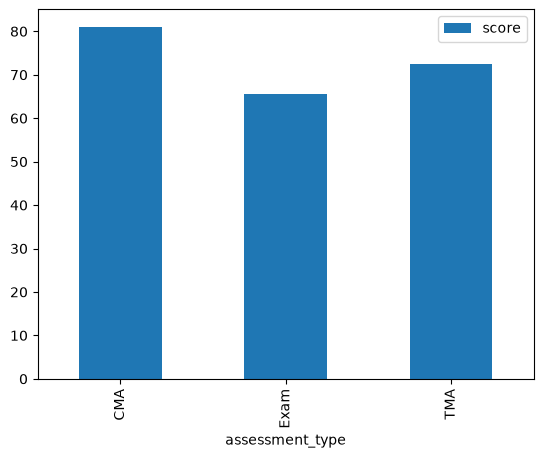

In [28]:
Assessment_Type_Score = pd.DataFrame(combinedfile.groupby("assessment_type")["score"].mean())
Assessment_Type_Score.plot(kind="bar")

TMA is the most common assessment type (96,916 rows), followed by CMA (69,956); exams are the least common (4,959). CMA has the highest observed mean score and exams the lowest. These are descriptive comparisons across different assessments and student groups.


Investigate the distribution of weight as well as the relationship between it and score. 

<Axes: ylabel='Frequency'>

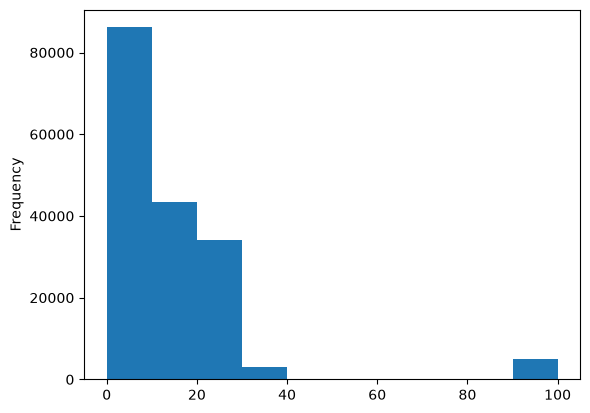

In [29]:
combinedfile["weight"].plot(kind="hist")

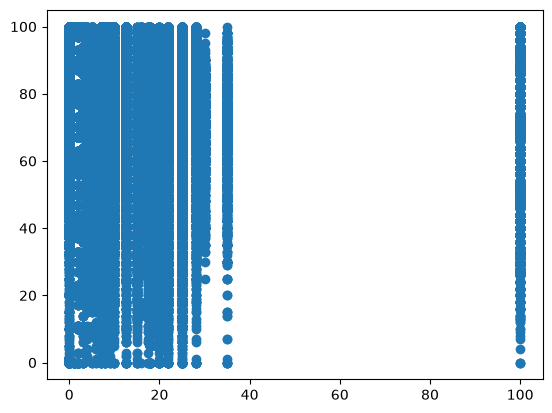

In [30]:
plt.scatter(combinedfile["weight"],combinedfile["score"])

The bulk of all assessments are weighted at 40% or below while a small portion are weighted in the 90-100% range. There is no clear relationship between weight and score. 

Investigate the distribution of gender as well as the relationship between it and the average score. 

In [31]:
combinedfile["gender"].value_counts()

gender
M    92750
F    79081
Name: count, dtype: int64

<Axes: xlabel='gender'>

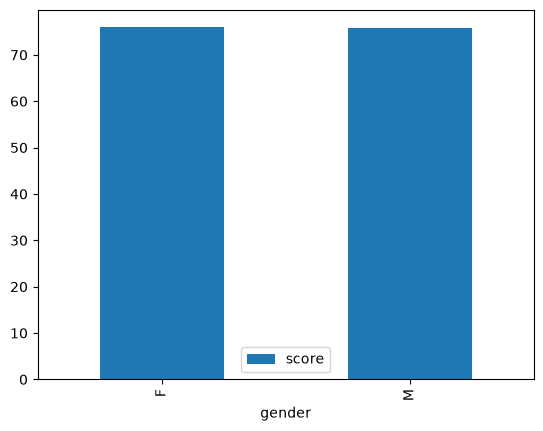

In [32]:
Gender_Score = pd.DataFrame(combinedfile.groupby("gender")["score"].mean())
Gender_Score.plot(kind="bar")

There are 92,750 male and 79,081 female assessment records, not that many distinct students. Compare observed means descriptively; this plot alone does not establish statistical significance or causation.


Investigate distribution of region as well as the relationship between it and the average score. 

In [33]:
combinedfile["region"].value_counts()

region
East Anglian Region     18099
Scotland                17761
South Region            17422
London Region           16185
North Western Region    13746
South West Region       13287
West Midlands Region    12860
East Midlands Region    12213
South East Region       11650
Wales                   11041
Yorkshire Region        10219
North Region            10121
Ireland                  7227
Name: count, dtype: int64

<Axes: xlabel='region'>

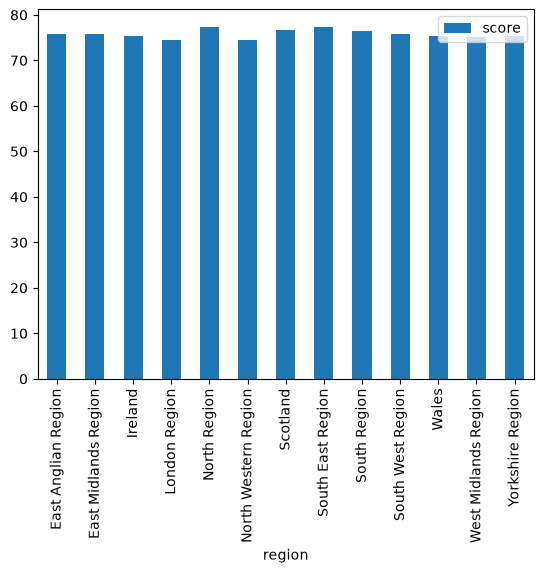

In [34]:
Region_Score = pd.DataFrame(combinedfile.groupby("region")["score"].mean())
Region_Score.plot(kind="bar")

The assessment records cover multiple regions. Differences between regional means are descriptive and may reflect differences in courses and student composition.


Investigate the distribution of highest_education as well as the relationship between it and average score. 

In [35]:
combinedfile["highest_education"].value_counts()

highest_education
A Level or Equivalent          78963
Lower Than A Level             62421
HE Qualification               27150
Post Graduate Qualification     1911
No Formal quals                 1386
Name: count, dtype: int64

<Axes: xlabel='highest_education'>

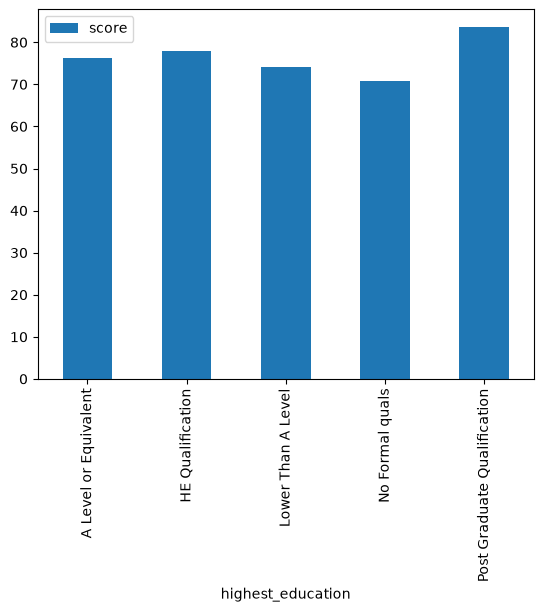

In [36]:
Education_Score = pd.DataFrame(combinedfile.groupby("highest_education")["score"].mean())
Education_Score.plot(kind="bar")

A Level or Equivalent is the most common while no formal qualifications is the least common. Post graduate qualification has the highest average score while no formal qualifications has the lowest. 

Investigate the distribution of imdb_band as well as the relationship between it and the average score. 

In [37]:
combinedfile["imd_band"].value_counts()

imd_band
30-40%     19020
20-30%     17312
40-50%     16870
50-60%     16785
10-20      16556
70-80%     16095
60-70%     15964
80-90%     15634
0-10%      15010
90-100%    14961
Unknown     7624
Name: count, dtype: int64

<Axes: xlabel='imd_band'>

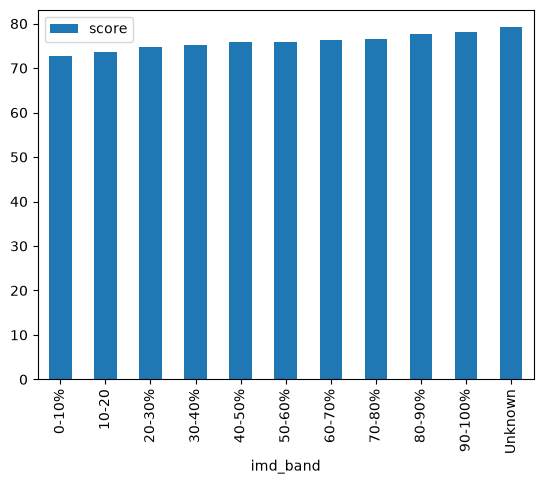

In [38]:
IMD_Score = pd.DataFrame(combinedfile.groupby("imd_band")["score"].mean())
IMD_Score.plot(kind="bar")

There is substantial variation in economic background. The difference in average mean scores by economic background is not drastic though the average is highest for the affluent backgrounds and lowest for the poorest backgrounds. 

Investigate the age_band distribution as well as the relationship between it and the average score. 

In [39]:
combinedfile["age_band"].value_counts()

age_band
0-35     118048
35-55     52648
55<=       1135
Name: count, dtype: int64

<Axes: xlabel='age_band'>

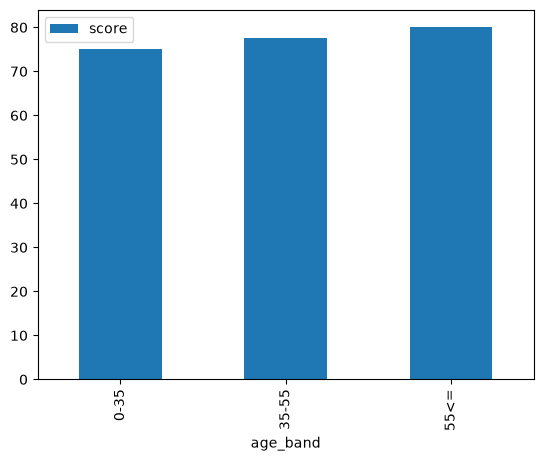

In [40]:
Age_Score = pd.DataFrame(combinedfile.groupby("age_band")["score"].mean())
Age_Score.plot(kind="bar")

The `0-35` band contains the most assessment records and `55<=` the fewest. The oldest band has the highest observed average score. Counts describe assessment rows; repeated student observations and group composition affect these comparisons.


Investigate the distribution of the number of previous attempts as well as the relationship between it and score.  

In [41]:
combinedfile["num_of_prev_attempts"].value_counts()

num_of_prev_attempts
0    153573
1     14748
2      2776
3       529
4       153
5        39
6        13
Name: count, dtype: int64

<Axes: xlabel='num_of_prev_attempts'>

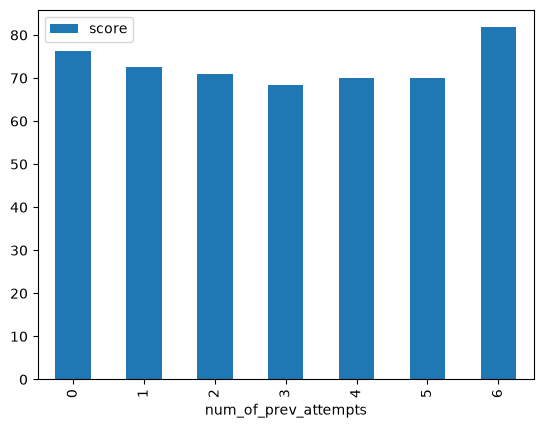

In [42]:
Attempts_Score = pd.DataFrame(combinedfile.groupby("num_of_prev_attempts")["score"].mean())
Attempts_Score.plot(kind="bar")

Most assessment records have zero or one recorded previous attempt. The groups with several previous attempts are small; their means should not be treated as evidence that additional attempts improve performance. Display counts alongside means.


Investigate the distribution of studied credits as well as the relationship between it and the score. 

<Axes: ylabel='Frequency'>

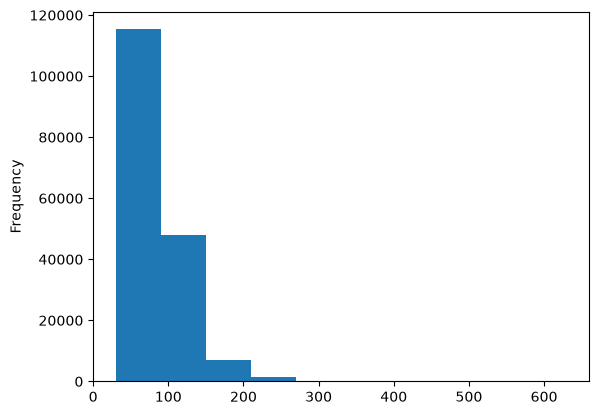

In [43]:
combinedfile["studied_credits"].plot(kind="hist")

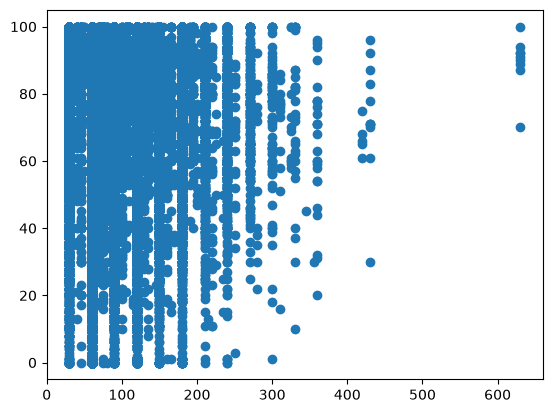

In [44]:
plt.scatter(combinedfile["studied_credits"],combinedfile["score"])

150 or less credits is the most common. No clear relationship between number of credits and score. 

Investigate the distribution of disability as well as the relationship between it and the average score. 

In [45]:
combinedfile["disability"].value_counts()

disability
N    156998
Y     14833
Name: count, dtype: int64

<Axes: xlabel='disability'>

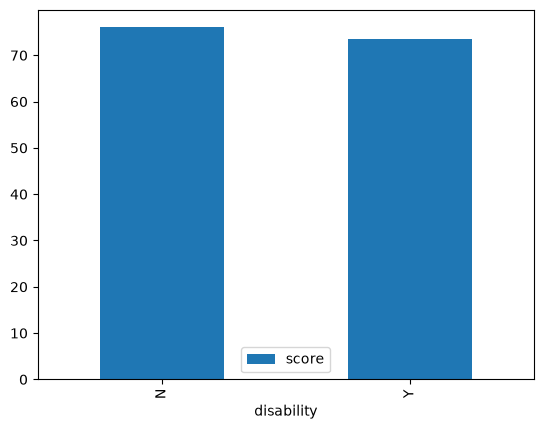

In [46]:
Disability_Score = pd.DataFrame(combinedfile.groupby("disability")["score"].mean())
Disability_Score.plot(kind="bar")

Most assessment records have disability coded N. Their observed mean score is slightly higher than records coded Y. This is a descriptive association, not evidence of significance or a causal effect.


Save the cleaned file in csv format. 

In [47]:
combinedfile.to_csv(DATA_DIR / "combinedfile_cleaned.csv",index=False)

## Data quality and repeated observations

Check target range and duplicate student/assessment pairs, and distinguish student
counts from assessment counts. Rows with missing targets cannot be used for supervised
score regression. Scores from non-submitted assessments are not observed, so results
do not describe all enrolled students or predict non-submission.


In [48]:
assert combinedfile['score'].notna().all()
assert combinedfile['score'].between(0, 100).all()
assert not combinedfile.duplicated(['id_student', 'id_assessment']).any()
display(pd.Series({
    'assessment_records': len(combinedfile),
    'distinct_students': combinedfile['id_student'].nunique(),
    'distinct_assessments': combinedfile['id_assessment'].nunique(),
    'missing_deadlines_retained': combinedfile['date'].isna().sum(),
    'mean_score': combinedfile['score'].mean(),
    'median_score': combinedfile['score'].median(),
    'score_standard_deviation': combinedfile['score'].std(),
}, name='Cleaned dataset summary'))
display(combinedfile.groupby('id_student').size().describe().rename('Assessments per student'))
for column in ['assessment_type', 'code_module', 'num_of_prev_attempts']:
    print(column)
    display(combinedfile.groupby(column).agg(
        assessments=('score', 'size'), students=('id_student', 'nunique'),
        mean_score=('score', 'mean'), median_score=('score', 'median'),
        score_std=('score', 'std')))


assessment_records            171831.000000
distinct_students              23291.000000
distinct_assessments             188.000000
missing_deadlines_retained      2865.000000
mean_score                        75.815714
median_score                      80.000000
score_standard_deviation          18.812127
Name: Cleaned dataset summary, dtype: float64

count    23291.000000
mean         7.377571
std          4.195367
min          1.000000
25%          4.000000
50%          7.000000
75%         11.000000
max         28.000000
Name: Assessments per student, dtype: float64

assessment_type


,assessments,students,mean_score,median_score,score_std
assessment_type,,,,,
CMA,69956,14364,81.035722,82.0,17.822523
Exam,4959,4633,65.572898,67.0,20.579186
TMA,96916,22599,72.571908,76.0,18.464876


code_module


,assessments,students,mean_score,median_score,score_std
code_module,,,,,
AAA,3104,677,69.001289,71.0,12.990812
BBB,42497,5934,76.704779,80.0,20.170682
CCC,18792,3317,73.304012,78.0,22.559225
DDD,30244,4669,70.044604,74.0,20.133916
EEE,7846,2267,81.166454,85.0,15.013912
FFF,54149,6038,77.740032,80.0,14.778974
GGG,15199,2104,79.692875,80.0,19.231851


num_of_prev_attempts


,assessments,students,mean_score,median_score,score_std
num_of_prev_attempts,,,,,
0,153573,21066,76.252193,80.0,18.651656
1,14748,2317,72.542718,76.0,19.509921
2,2776,476,70.866354,74.0,20.356139
3,529,91,68.283554,71.0,22.074232
4,153,25,70.026144,75.0,18.888157
5,39,9,69.948718,76.0,21.388571
6,13,2,81.769231,81.0,6.247051


## Modeling handoff

Use `score` as the target and exclude `final_result` from predictive features: it is
a later course outcome. Keep student IDs for splitting, not as predictors. The model
notebook uses disjoint students for training, validation, and testing, fits its
preprocessors on training data, and reports constant and course-context baselines.
Full-dataset summary statistics above are descriptive, not fitted baseline predictions.
Future-course forecasting requires a separate chronological design.
